# Forecasting Daily Traffic Incidents on Pasig City's Major Roads

**IT 201 – Platform Technologies | Final Case Study | Regression notebook**

**Course:** IT 201 – Platform Technologies, College of Computer Studies, Pamantasan ng Lungsod ng Pasig  
**Instructor:** Racquel Cortez

---

## Phase I. Problem Identification and Data Requirements

**Problem.** Vehicular accidents, collisions, stalled vehicles, and road works block lanes and slow traffic on Pasig City's major roads. Enforcers and tow trucks are placed where incidents are expected, but the expected number is a judgement call, not a forecast.

**Problem Validation.** To validate the problem, the group reviewed published reports. MMDA's Metro Manila Accident Recording and Analysis System (MMARAS) recorded 121,771 road crashes in Metro Manila in 2019, about 334 a day, with 394 deaths (Top Gear Philippines, 2020). The same MMARAS data showed C5 as Metro Manila's deadliest road for the third year running, with 31 fatalities, 1,136 non-fatal injuries, and 7,568 property-damage cases in 2019 (Chua, 2020). Our own dataset shows that MMDA reported 1,611 incidents on C5, Ortigas Avenue, and Marcos Highway within Pasig City over about 18 months (August 2018 to February 2020). MMARAS counts crashes while our data counts incidents that MMDA tweeted, so the two are not the same measure, but both show that incidents on these roads are frequent and well documented. News reports on MMDA data also show that most Metro Manila road crashes in 2024 took place on EDSA and C5 (Sigales, 2025), and that traffic cost the Philippines about P3.5 billion per day in 2018 (Wheels.ph, 2019). Because enforcers and tow trucks are limited, knowing how many incidents to expect on each road and day is a practical planning question. (See References at the end of this notebook.)

**Relevance to Pasig City and PLP.** C5, Ortigas Avenue, and Marcos Highway are major roads that serve Pasig City, and 1,723 of the dataset's 17,312 rows (10%) are incidents that MMDA placed in Pasig City. The results are meant for the Pasig City traffic management office and the MMDA personnel who cover Pasig, and they also matter to Pasig commuters, including PLP students and staff who travel on these roads.

**Who is affected and why it matters.** Commuters, motorists, and public transport riders lose time and face risk at the incident site. MMDA and Pasig City traffic management personnel must decide where to send limited enforcers and tow trucks.

**Objectives**

1. Prepare a clean road-day dataset from public MMDA alerts.
2. Explore how incidents vary by major road, day of week, and hour.
3. Train regression models and compare them with a simple per-road average.
4. Judge whether the best model is useful for planning and state its limits.

**Research Questions**

- 1. How do incident counts differ by major road and day of week?
- 2. Does activity in the previous 7 days help predict today's count?
- 3. Does a regression model beat a per-road average?
- 4. Is it accurate enough for planning?

**Data needed.** Date, location (major road), time, and incident details of MMDA-reported traffic incidents in Pasig City.

**Machine Learning Task and Algorithm.** Regression (the target is a count). Linear Regression, Poisson Regression and Random Forest Regressor, compared against a baseline of each major road's average count.

**Intended use.** Results can help MMDA and the Pasig City traffic management office plan the weekly placement of enforcers and tow trucks by major road and day.

### Project summary

**Title of the study:** Forecasting Daily Traffic Incidents on Pasig City's Major Roads (C5, Ortigas Avenue, Marcos Highway)

**Source of data:** Brotoisworo, P. (n.d.). *Manila Traffic Incident Data: Incidents Reported by the Metro Manila Development Authority Twitter Page* [Data set]. Kaggle. https://www.kaggle.com/datasets/esparko/mmda-traffic-incident-data (license CC BY-NC-SA 4.0). The file used is `data_mmda_traffic_spatial.csv`. The original data are MMDA ALERT tweets from the MMDA Twitter page.

**Raw dataset:** 17,312 rows × 13 columns covering Metro Manila (20 Aug 2018 – 27 Dec 2020). Only the 1,723 rows where `City == "Pasig City"` are used. After cleaning and reshaping, the **prepared dataset has 1,656 rows × 8 columns** (552 days × 3 major roads).

| Column | Meaning |
|---|---|
| Date, Time | When the alert was posted / incident reported |
| City | City where MMDA placed the incident |
| Location | Road segment or landmark named in the alert |
| Latitude, Longitude | Geocoded coordinates of the location (about 100 distinct pairs for Pasig, so location-level, not exact GPS) |
| High_Accuracy | 1 if the geocoding is precise, 0 otherwise |
| Direction | NB / SB / EB / WB |
| Type | Incident type (vehicular accident, stalled vehicle, multiple collision, ...) |
| Lanes_Blocked | Number of lanes occupied |
| Involved | Vehicles involved |
| Tweet, Source | Alert text and URL of the tweet |

**Unit of analysis (after preparation):** one row per **major road per day** (C5, Ortigas, Marcos Highway).

**Selected features (independent variables):** major road, day of week, month, the major road's incident count 7 days earlier (`Incidents_Lag7`), and its average over the previous 7 days (`Incidents_Roll7`).

**Target (dependent variable):** `Incidents` – number of MMDA-reported incidents on that major road that day.

**Objective:** use regression to predict how many incidents to expect on each major road each day, so that the MMDA and Pasig City's traffic management office can plan where to place enforcers and tow trucks.

**Requirements:** Python 3 with pandas, numpy, matplotlib and scikit-learn 1.2 or newer (the versions used are printed in Phase II). Keep `data_mmda_traffic_spatial.csv` in the same folder as this notebook.

**Important limitations (see the conclusion):** the data holds only incidents that MMDA tweeted, not all incidents; the dataset's author notes that it does not represent all incidents and is biased toward national roads such as EDSA and C5; March 2020 onward is excluded from modeling because the counts fall sharply (the author reports a collection gap in early 2020, and traffic also fell during the lockdown).

## Phase II. Data Gathering

- **Method:** publicly available dataset with a documented source (*Manila Traffic Incident Data*, Brotoisworo, Kaggle). The data are MMDA ALERT tweets collected through the Twitter API and parsed by the dataset author's Python script.
- **Collection period:** 20 August 2018 to 27 December 2020. **Records:** 17,312 raw rows and 13 columns for all of Metro Manila, of which 1,723 rows are for Pasig City (well above the 100-record classroom guideline).
- **Raw file:** `data_mmda_traffic_spatial.csv` is the original file, kept **unchanged** (the raw dataset deliverable). This notebook never overwrites it; all cleaning happens in memory, and the engineered data is saved to a new file.
- **Privacy and consent:** the records are public posts by a government agency. They contain no names, plate numbers or other personal details, only vehicle types and places, so no individual consent is needed. The license (CC BY-NC-SA 4.0) allows non-commercial use with attribution, which fits coursework.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)   # keep other warnings visible
RANDOM_STATE = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart styling (categorical hues in a fixed order; muted ink for text)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
ROAD_COLORS = {'C5': BLUE, 'ORTIGAS': ORANGE, 'MARCOS': AQUA}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False,
    # Explicit text colours so titles, labels and legends stay readable even when the
    # IDE (e.g. PyCharm dark theme) sets light text on a white figure background
    'text.color': INK, 'axes.titlecolor': INK, 'legend.labelcolor': INK,
    'savefig.facecolor': 'white', 'figure.edgecolor': 'white',
})

RAW_PATH = 'data_mmda_traffic_spatial.csv'
raw = pd.read_csv(RAW_PATH)

import sys, sklearn, matplotlib
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
print('Raw dataset dimensions:', raw.shape)
raw.head()

Python 3.14.0 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2
Raw dataset dimensions: (17312, 13)


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
0,2018-08-20,7:55 AM,Pasig City,ORTIGAS EMERALD,14.586343,121.061481,1,EB,VEHICULAR ACCIDENT,1.0,TAXI AND MC,MMDA ALERT: Vehicular accident at Ortigas Emer...,https://twitter.com/mmda/status/10313302019705...
1,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313462477459...
2,2018-08-20,9:13 AM,Makati City,EDSA ROCKWELL,14.559818,121.040737,1,SB,VEHICULAR ACCIDENT,1.0,SUV AND L300,MMDA ALERT: Vehicular accident at EDSA Rockwel...,https://twitter.com/mmda/status/10313589669896...
3,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313590696535...
4,2018-08-20,10:27 AM,San Juan,ORTIGAS CLUB FILIPINO,14.601846,121.046754,1,EB,VEHICULAR ACCIDENT,1.0,2 CARS,MMDA ALERT: Vehicular accident at Ortigas Club...,https://twitter.com/mmda/status/10313711248424...


## Phase III. Data Preparation

### 3.1 Data Information and Summary Statistics

In [2]:
print('Shape (rows, columns):', raw.shape)
raw.info()

Shape (rows, columns): (17312, 13)
<class 'pandas.DataFrame'>
RangeIndex: 17312 entries, 0 to 17311
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           17312 non-null  str    
 1   Time           17190 non-null  str    
 2   City           17125 non-null  str    
 3   Location       17289 non-null  str    
 4   Latitude       17312 non-null  float64
 5   Longitude      17312 non-null  float64
 6   High_Accuracy  17312 non-null  int64  
 7   Direction      16455 non-null  str    
 8   Type           17255 non-null  str    
 9   Lanes_Blocked  16625 non-null  float64
 10  Involved       16880 non-null  str    
 11  Tweet          17312 non-null  str    
 12  Source         17312 non-null  str    
dtypes: float64(3), int64(1), str(9)
memory usage: 1.7 MB


In [3]:
raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,17312,715,2018-10-17,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,17190,1484,7:40 AM,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,17125,15,Quezon City,8725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,17289,2977,EDSA SHAW TUNNEL,306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,17312.0,NaN,NaN,NaN,14.559448,0.822927,0.0,14.577625,14.603015,14.63291,14.735495
Longitude,17312.0,NaN,NaN,NaN,120.666794,6.812422,0.0,121.042734,121.053801,121.069619,121.119655
High_Accuracy,17312.0,NaN,NaN,NaN,0.955638,0.205905,0.0,1.0,1.0,1.0,1.0
Direction,16455,9,NB,6585,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,17255,493,VEHICULAR ACCIDENT,11775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lanes_Blocked,16625.0,NaN,NaN,NaN,1.097624,0.302237,1.0,1.0,1.0,1.0,6.0


In [4]:
print('First 5 rows'); display(raw.head())
print('Last 5 rows');  display(raw.tail())

First 5 rows


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
0,2018-08-20,7:55 AM,Pasig City,ORTIGAS EMERALD,14.586343,121.061481,1,EB,VEHICULAR ACCIDENT,1.0,TAXI AND MC,MMDA ALERT: Vehicular accident at Ortigas Emer...,https://twitter.com/mmda/status/10313302019705...
1,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313462477459...
2,2018-08-20,9:13 AM,Makati City,EDSA ROCKWELL,14.559818,121.040737,1,SB,VEHICULAR ACCIDENT,1.0,SUV AND L300,MMDA ALERT: Vehicular accident at EDSA Rockwel...,https://twitter.com/mmda/status/10313589669896...
3,2018-08-20,8:42 AM,Mandaluyong,EDSA GUADIX,14.589432,121.057243,1,NB,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0,L300,MMDA ALERT: Stalled L300 due to mechanical pro...,https://twitter.com/mmda/status/10313590696535...
4,2018-08-20,10:27 AM,San Juan,ORTIGAS CLUB FILIPINO,14.601846,121.046754,1,EB,VEHICULAR ACCIDENT,1.0,2 CARS,MMDA ALERT: Vehicular accident at Ortigas Club...,https://twitter.com/mmda/status/10313711248424...


Last 5 rows


,Date,Time,City,Location,Latitude,Longitude,High_Accuracy,Direction,Type,Lanes_Blocked,Involved,Tweet,Source
17307,2020-12-27,12:59 PM,Manila,QUIRINO GUAZON PETRON,14.585503,120.993783,1,SB,VEHICULAR ACCIDENT,1.0,MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT QUIRINO GUAZ...,https://twitter.com/mmda/status/13430604432589...
17308,2020-12-27,3:08 PM,Makati City,EDSA ESTRELLA,14.559818,121.040737,1,NB,STALLED VAN DUE TO TIRE PROBLEM,1.0,VAN,MMDA ALERT: STALLED VAN DUE TO TIRE PROBLEM AT...,https://twitter.com/mmda/status/13430967348098...
17309,2020-12-27,3:23 PM,Quezon City,EDSA P TUAZON FLYOVER,14.616404,121.052548,1,SB,VEHICULAR ACCIDENT,1.0,CAR AND MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT EDSA P. TUAZ...,https://twitter.com/mmda/status/13430968412152...
17310,2020-12-27,7:46 PM,Quezon City,ORTIGAS AVE EDSA POEA,14.593548,121.058028,1,WB,STALLED MULTICAB DUE TO MECHANICAL PROBLEM,1.0,MULTICAB,MMDA ALERT: STALLED MULTICAB DUE TO MECHANICAL...,https://twitter.com/mmda/status/13431795574073...
17311,2020-12-27,9:39 PM,Manila,LEGARDA STA CATALINA COLLEGE,14.600902,120.997352,1,WB,VEHICULAR ACCIDENT,1.0,MOTORCYCLE,MMDA ALERT: VEHICULAR ACCIDENT AT LEGARDA STA....,https://twitter.com/mmda/status/13431936109723...


In [5]:
print('Missing values per column (whole file):')
print(raw.isnull().sum())
print()
print('Records per city (top 8):')
print(raw['City'].value_counts(dropna=False).head(8))
print()
print('Date range:', raw['Date'].min(), '->', raw['Date'].max())
print('Duplicate rows (all columns):', raw.duplicated().sum())

Missing values per column (whole file):
Date               0
Time             122
City             187
Location          23
Latitude           0
Longitude          0
High_Accuracy      0
Direction        857
Type              57
Lanes_Blocked    687
Involved         432
Tweet              0
Source             0
dtype: int64

Records per city (top 8):
City
Quezon City    8725
Mandaluyong    2978
Makati City    2431
Pasig City     1723
Pasay City      445
Manila          354
NaN             187
San Juan        121
Name: count, dtype: int64

Date range: 2018-08-20 -> 2020-12-27
Duplicate rows (all columns): 0


In [6]:
pasig_raw = raw[raw['City'] == 'Pasig City']
print('Pasig City rows:', pasig_raw.shape[0])
print()
print('Missing values in the Pasig rows:')
print(pasig_raw.isnull().sum()[lambda s: s > 0])
print()
print('Distinct Location spellings:', pasig_raw['Location'].nunique(), '| distinct Type labels:', pasig_raw['Type'].nunique())
print('Lanes_Blocked values:', pasig_raw['Lanes_Blocked'].value_counts(dropna=False).to_dict())
print('High_Accuracy values:', pasig_raw['High_Accuracy'].value_counts().to_dict())

Pasig City rows: 1723

Missing values in the Pasig rows:
Time              8
Direction        46
Type              5
Lanes_Blocked    49
Involved         40
dtype: int64

Distinct Location spellings: 242 | distinct Type labels: 111
Lanes_Blocked values: {1.0: 1543, 2.0: 130, nan: 49, 6.0: 1}
High_Accuracy values: {1: 1675, 0: 48}


**Observations:**
- The raw file covers all of Metro Manila; Pasig City is one of several cities.
- Some columns have missing values (`Time`, `Direction`, `Type`, `Lanes_Blocked`, `Involved`, `City`). The model only needs the date, the major road, and the counts, so these gaps matter mostly for the exploratory charts.
- There are many different spellings of locations and incident types, so they must be grouped before analysis.

### 3.2 Data Cleaning

Each step below states **what** was done and **why**.

In [7]:
# Keep Pasig City records only
pasig = raw[raw['City'] == 'Pasig City'].copy()
print(f'Pasig filter: {len(raw):,} -> {len(pasig):,} rows')

# Convert the date (the original uses ISO format YYYY-MM-DD)
pasig['Date'] = pd.to_datetime(pasig['Date'], format='%Y-%m-%d')
print('Date range:', pasig['Date'].min().date(), '->', pasig['Date'].max().date())

Pasig filter: 17,312 -> 1,723 rows
Date range: 2018-08-20 -> 2020-12-26


In [8]:
# Hour of the incident. Parse the Time column; where it is missing or malformed
#     (e.g. '9:00PM', '8:26M', '10:06'), recover the time from the alert text ("... as of 7:55 AM").
TIME_RE = re.compile(r'(\d{1,2})\s*:\s*(\d{2})\s*\.?\s*([AaPp])\.?\s*[Mm]?')

def to_hour(text):
    m = TIME_RE.search(str(text))
    if not m:
        return np.nan
    h = int(m.group(1))
    if not 1 <= h <= 12:
        return np.nan
    return h % 12 + (12 if m.group(3).upper() == 'P' else 0)

hour_from_time = pasig['Time'].apply(to_hour)
hour_from_tweet = pasig['Tweet'].apply(to_hour)
pasig['Hour'] = hour_from_time.fillna(hour_from_tweet)
print('Time column unusable in', hour_from_time.isna().sum(), 'rows;',
      'recovered from the tweet text in', (hour_from_time.isna() & hour_from_tweet.notna()).sum(), 'rows;',
      'still missing:', pasig['Hour'].isna().sum())

Time column unusable in 10 rows; recovered from the tweet text in 3 rows; still missing: 7


In [9]:
# Remove duplicate records. The same incident is sometimes tweeted twice.
n0 = len(pasig)
pasig = pasig.drop_duplicates(subset='Source')
n1 = len(pasig)
key = ['Date', 'Time', 'Location', 'Direction', 'Type']
pasig = pasig.drop_duplicates(subset=key)
n2 = len(pasig)
print(f'Duplicate tweets removed (same URL): {n0 - n1}')
print(f'    Same incident tweeted twice (same date, time, location, direction, type): {n1 - n2}')
print(f'    Rows after de-duplication: {n2:,}')

Duplicate tweets removed (same URL): 3
    Same incident tweeted twice (same date, time, location, direction, type): 35
    Rows after de-duplication: 1,685


In [10]:
# Group the 242 location spellings into the major roads.
loc = pasig['Location'].str.upper().str.strip()
pasig['MajorRoad'] = np.select(
    [loc.str.match(r'^C-?5'), loc.str.startswith('MARCOS'), loc.str.startswith('ORTIGAS')],
    ['C5', 'MARCOS', 'ORTIGAS'], default='OTHER')
print(pasig['MajorRoad'].value_counts())
print()
print('Examples of rows left out as OTHER (EDSA, Meralco Onyx, ADB, Poveda, ...):')
print(loc[pasig['MajorRoad'] == 'OTHER'].value_counts().head(8).to_dict())

MajorRoad
C5         1025
ORTIGAS     326
MARCOS      260
OTHER        74
Name: count, dtype: int64

Examples of rows left out as OTHER (EDSA, Meralco Onyx, ADB, Poveda, ...):
{'MERALCO ONYX': 11, 'FVR ROAD CAMP ATIENZA': 4, 'EDSA PIONEER GO HOTEL': 2, 'ADB POVEDA': 2, 'EDSA BONI AMBERS': 2, 'EDSA GO HOTEL PIONEER': 2, 'COMMONWEALTH ZUZUARREGUI': 1, 'COMMONWEALTH TANDANG SORA': 1}


In [11]:
# Keep the three major roads. (Rows with a missing City, e.g. many on Marcos Highway, cannot be
#     assigned to Pasig and are not used; see the limitations.)
inc = pasig[pasig['MajorRoad'] != 'OTHER'].copy()
print('Clean incident table:', inc.shape)
print('Missing values left (used only for EDA):')
print(inc[['Hour', 'Direction', 'Type', 'Lanes_Blocked', 'Involved']].isnull().sum().to_dict())

Clean incident table: (1611, 15)
Missing values left (used only for EDA):
{'Hour': 7, 'Direction': 37, 'Type': 5, 'Lanes_Blocked': 42, 'Involved': 39}


In [12]:
# Validate ranges, units, dates and categories on the clean incident table
checks = {
    'Latitude is inside the Pasig area (14.50 to 14.66)': inc['Latitude'].between(14.50, 14.66).all(),
    'Longitude is inside the Pasig area (121.03 to 121.13)': inc['Longitude'].between(121.03, 121.13).all(),
    'High_Accuracy is 0 or 1': inc['High_Accuracy'].isin([0, 1]).all(),
    'Direction is NB, SB, EB or WB (when present)': inc['Direction'].dropna().isin(['NB', 'SB', 'EB', 'WB']).all(),
    'Lanes_Blocked is between 1 and 6 (when present)': inc['Lanes_Blocked'].dropna().between(1, 6).all(),
    'Hour is between 0 and 23 (when present)': inc['Hour'].dropna().between(0, 23).all(),
    'Dates fall between Aug 2018 and Dec 2020': inc['Date'].between('2018-08-01', '2020-12-31').all(),
}
for rule, ok in checks.items():
    print(('PASS   ' if ok else 'CHECK  ') + rule)

PASS   Latitude is inside the Pasig area (14.50 to 14.66)
PASS   Longitude is inside the Pasig area (121.03 to 121.13)
PASS   High_Accuracy is 0 or 1
PASS   Direction is NB, SB, EB or WB (when present)
PASS   Lanes_Blocked is between 1 and 6 (when present)
PASS   Hour is between 0 and 23 (when present)
PASS   Dates fall between Aug 2018 and Dec 2020


**Cleaning decisions and justification**

| Step | Issue found | Treatment | Justification | Rows after |
|---|---|---|---|---|
| 1 | The file covers all of Metro Manila | Kept rows where `City == "Pasig City"` | The study is about Pasig City | 1,723 |
| 2 | `Date` is stored as text | Converted to a date type | Needed for day of week, month and lag features | 1,723 |
| 3 | `Time` unusable in 10 rows (8 missing, 2 malformed such as `8:26M` and `10:06`) | Recovered the hour from the alert text in 3 rows; 7 stay missing | Hours only feed one exploratory chart, so these rows were kept | 1,723 |
| 4 | 3 repeated tweets (same URL) and 35 cases of the same incident tweeted twice | Removed 38 duplicates | Incidents must not be double-counted | 1,685 |
| 5 | 242 different location spellings | Grouped into C5 (1,025 rows), Ortigas (326) and Marcos Highway (260); excluded 74 rows (EDSA, Meralco Onyx, ADB, Poveda, etc.) | Daily counts need enough incidents per group; the other locations are too scattered to model | 1,611 |
| 6 | Missing `Direction`, `Type`, `Lanes_Blocked` and `Involved` | Not imputed | They do not affect the daily-count target | 1,611 |
| 7 | Possible invalid values | Validated ranges and categories (coordinates inside the Pasig area, `High_Accuracy` 0 or 1, valid directions, lanes blocked 1–6, hours 0–23, dates within the data period) | Catch invalid values; all checks passed | 1,611 |

### 3.3 Data Engineering and Pre-Processing

**Why aggregate:** the original rows are individual incidents. To predict *how many* incidents to expect, the data is reshaped to **one row per major road per day**, and days with no incident are added explicitly as zeros (the original file only lists days with at least one incident).

**Why stop at 29 Feb 2020:** the counts fall sharply from March 2020. The dataset's author reports a gap in early 2020 caused by pandemic-related difficulties and a code upgrade, and traffic itself also fell during the lockdown, so those months are not comparable with the earlier ones.

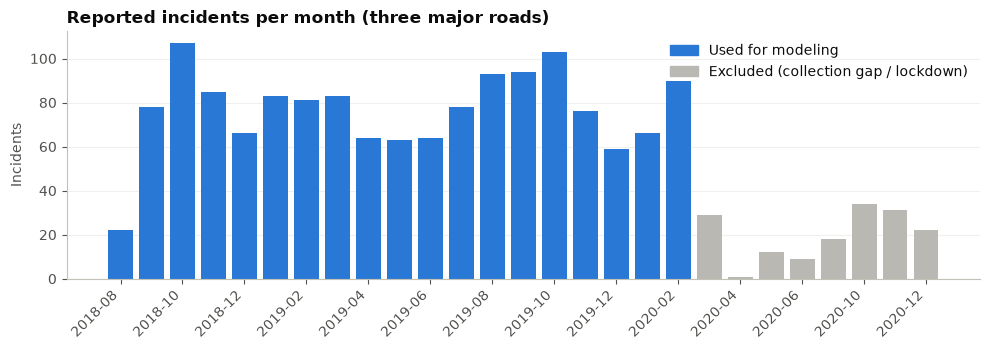

In [13]:
monthly = inc.groupby(inc['Date'].dt.to_period('M')).size()
CUTOFF = pd.Timestamp('2020-02-29')
used = [p.to_timestamp() <= CUTOFF for p in monthly.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(monthly)), monthly.values, color=[BLUE if u else GREY for u in used],
       width=0.8)
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels([str(p) for p in monthly.index[::2]], rotation=45, ha='right')
ax.set_title('Reported incidents per month (three major roads)')
ax.set_ylabel('Incidents')
ax.legend(handles=[Patch(color=BLUE, label='Used for modeling'), Patch(color=GREY, label='Excluded (collection gap / lockdown)')],
          loc='upper right')
plt.tight_layout(); plt.show()

In [14]:
# Build the road-day table (with explicit zero-incident days)
START = inc['Date'].min().normalize()
major_roads = ['C5', 'ORTIGAS', 'MARCOS']
model_inc = inc[inc['Date'] <= CUTOFF]
days = pd.date_range(START, CUTOFF)

counts = model_inc.groupby(['Date', 'MajorRoad']).size()
grid = (counts.reindex(pd.MultiIndex.from_product([days, major_roads], names=['Date', 'MajorRoad']), fill_value=0)
        .rename('Incidents').reset_index()
        .sort_values(['MajorRoad', 'Date']).reset_index(drop=True))
print('Road-day grid:', grid.shape, '| days:', len(days), '| major roads:', len(major_roads))

# Derived variables (each has a clear purpose)
grid['DayOfWeek'] = grid['Date'].dt.dayofweek          # 0 = Monday ... 6 = Sunday
grid['Month'] = grid['Date'].dt.month
grid['IsWeekend'] = (grid['DayOfWeek'] >= 5).astype(int)
g = grid.groupby('MajorRoad')['Incidents']
grid['Incidents_Lag7'] = g.shift(7)                                            # same weekday last week
grid['Incidents_Roll7'] = g.transform(lambda s: s.shift(1).rolling(7).mean())  # average of the previous 7 days (excludes today)

# The first 7 days have no history, so they are dropped
eng = (grid.dropna().sort_values(['Date', 'MajorRoad']).reset_index(drop=True)
       [['Date', 'MajorRoad', 'DayOfWeek', 'Month', 'IsWeekend', 'Incidents_Lag7', 'Incidents_Roll7', 'Incidents']])
eng['Incidents_Lag7'] = eng['Incidents_Lag7'].astype(int)
print('Engineered dataset:', eng.shape, '| missing values:', int(eng.isnull().sum().sum()))

Road-day grid: (1677, 3) | days: 559 | major roads: 3
Engineered dataset: (1656, 8) | missing values: 0


In [15]:
# Outlier check on the target
print(eng['Incidents'].describe())
print()
print('Highest road-days:')
print(eng.nlargest(5, 'Incidents')[['Date', 'MajorRoad', 'Incidents']].to_string(index=False))

count    1656.000000
mean        0.871981
std         1.169827
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         7.000000
Name: Incidents, dtype: float64

Highest road-days:
      Date MajorRoad  Incidents
2019-01-16        C5          7
2019-02-19        C5          7
2018-09-29        C5          6
2018-10-12        C5          6
2018-10-16        C5          6


In [16]:
# Save the engineered dataset (deliverable)
eng.to_csv('engineered_pasig_major_road_day.csv', index=False)
print('Saved engineered_pasig_major_road_day.csv with dimensions', eng.shape)

Saved engineered_pasig_major_road_day.csv with dimensions (1656, 8)


In [17]:
# Encoding and scaling (preview). The same steps run inside the model pipeline in V.2,
#     where they are re-fitted for every cross-validation fold, so nothing from the test period leaks in.
SPLIT_DATE = pd.Timestamp('2019-10-01')
fit_part = eng[eng['Date'] < SPLIT_DATE]                       # fit on the training period only
cat_cols = ['MajorRoad', 'DayOfWeek', 'Month']
num_cols = ['Incidents_Lag7', 'Incidents_Roll7']

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(fit_part[cat_cols])
scaler = StandardScaler().fit(fit_part[num_cols])

enc_preview = pd.DataFrame(encoder.transform(eng[cat_cols]), columns=encoder.get_feature_names_out(cat_cols))
scaled_preview = pd.DataFrame(scaler.transform(eng[num_cols]), columns=[c + '_scaled' for c in num_cols])
preview = pd.concat([eng[['Date']], enc_preview, scaled_preview], axis=1)

print('One-hot columns:', enc_preview.shape[1], '| model input columns in total:', preview.shape[1] - 1)
print('Scaled features on the training period (mean ~0, std ~1):',
      scaler.transform(fit_part[num_cols]).mean(axis=0).round(2), scaler.transform(fit_part[num_cols]).std(axis=0).round(2))
preview.head()

One-hot columns: 22 | model input columns in total: 24
Scaled features on the training period (mean ~0, std ~1): [-0.  0.] [1. 1.]


,Date,MajorRoad_C5,MajorRoad_MARCOS,MajorRoad_ORTIGAS,DayOfWeek_0,DayOfWeek_1,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12,Incidents_Lag7_scaled,Incidents_Roll7_scaled
0,2018-08-27,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.973945,-0.021826
1,2018-08-27,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.751123,-0.866710
2,2018-08-27,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.111411,-0.655489
3,2018-08-28,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.751123,-0.444268
4,2018-08-28,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.111411,-0.655489


**Pre-processing decisions:**
- **Outliers:** the largest counts are plausible busy days, not errors, so they were **kept**.
- **Encoding and scaling:** major road, day of week and month are one-hot encoded and the two lag features are standardized. The step is previewed in the encoding and scaling cell of 3.3 and applied **inside the model pipeline** (5.2). They are fitted on the training data only, so no information from the test period leaks into training.
- **Derived variables:** `IsWeekend` is saved for reference but not used as a model feature (it duplicates `DayOfWeek`). The two lag features are the only history-based features.

## Phase IV. Exploratory Data Analysis (EDA)

### 4.1 First and last five rows and descriptive statistics

In [18]:
print('First 5 rows'); display(eng.head())
print('Last 5 rows');  display(eng.tail())
print('Descriptive statistics'); display(eng.describe().T)

First 5 rows


,Date,MajorRoad,DayOfWeek,Month,IsWeekend,Incidents_Lag7,Incidents_Roll7,Incidents
0,2018-08-27,C5,0,8,0,2,0.857143,0
1,2018-08-27,MARCOS,0,8,0,0,0.285714,1
2,2018-08-27,ORTIGAS,0,8,0,1,0.428571,1
3,2018-08-28,C5,1,8,0,0,0.571429,3
4,2018-08-28,MARCOS,1,8,0,1,0.428571,0


Last 5 rows


,Date,MajorRoad,DayOfWeek,Month,IsWeekend,Incidents_Lag7,Incidents_Roll7,Incidents
1651,2020-02-28,MARCOS,4,2,0,0,0.142857,1
1652,2020-02-28,ORTIGAS,4,2,0,0,0.000000,2
1653,2020-02-29,C5,5,2,1,0,1.857143,2
1654,2020-02-29,MARCOS,5,2,1,0,0.285714,1
1655,2020-02-29,ORTIGAS,5,2,1,0,0.285714,1


Descriptive statistics


,count,mean,min,25%,50%,75%,max,std
Date,1656,2019-05-29 12:00:00,2018-08-27 00:00:00,2019-01-11 18:00:00,2019-05-29 12:00:00,2019-10-14 06:00:00,2020-02-29 00:00:00,NaN
DayOfWeek,1656.0,2.994565,0.0,1.0,3.0,5.0,6.0,1.99833
Month,1656.0,6.871377,1.0,3.0,8.0,10.0,12.0,3.787051
IsWeekend,1656.0,0.28442,0.0,0.0,0.0,1.0,1.0,0.451274
Incidents_Lag7,1656.0,0.865942,0.0,0.0,0.0,1.0,7.0,1.166563
Incidents_Roll7,1656.0,0.866287,0.0,0.428571,0.571429,1.142857,3.428571,0.702222
Incidents,1656.0,0.871981,0.0,0.0,0.0,1.0,7.0,1.169827


### 4.2 Distribution of the target and frequency of categories

In [19]:
print('Distribution of the target (road-days by number of incidents):')
dist = eng['Incidents'].clip(upper=4).value_counts().sort_index()
dist.index = [str(i) if i < 4 else '4+' for i in dist.index]
print(dist.to_string())
print()
print('Road-days per major road:'); print(eng['MajorRoad'].value_counts().to_string())

Distribution of the target (road-days by number of incidents):
0     843
1     436
2     229
3      78
4+     70

Road-days per major road:
MajorRoad
C5         552
MARCOS     552
ORTIGAS    552


### 4.3 Data Visualizations

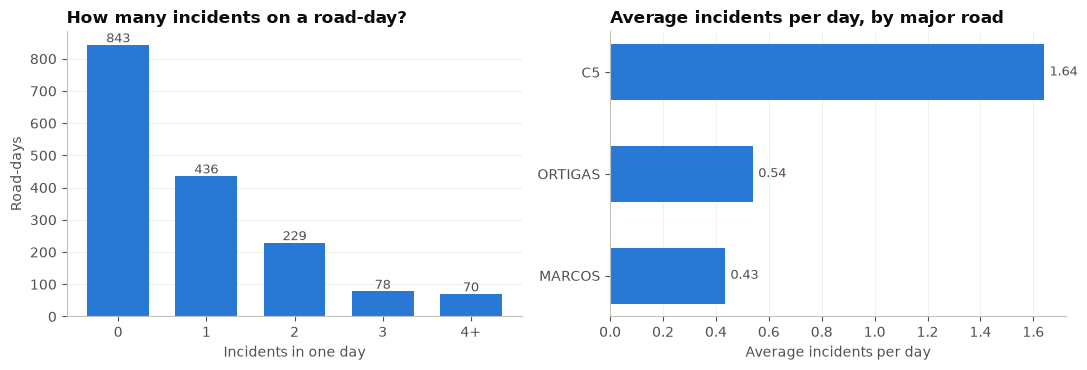

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (a) target distribution
ax = axes[0]
ax.bar(dist.index, dist.values, color=BLUE, width=0.7)
for i, v in enumerate(dist.values):
    ax.text(i, v + 8, f'{v:,}', ha='center', color=MUTED, fontsize=9)
ax.set_title('How many incidents on a road-day?')
ax.set_xlabel('Incidents in one day'); ax.set_ylabel('Road-days')

# (b) average incidents by major road
ax = axes[1]
m = eng.groupby('MajorRoad')['Incidents'].mean().sort_values()
ax.barh(m.index, m.values, color=BLUE, height=0.55)
for i, v in enumerate(m.values):
    ax.text(v + 0.02, i, f'{v:.2f}', va='center', color=MUTED, fontsize=9)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Average incidents per day, by major road')
ax.set_xlabel('Average incidents per day')
plt.tight_layout(); plt.show()

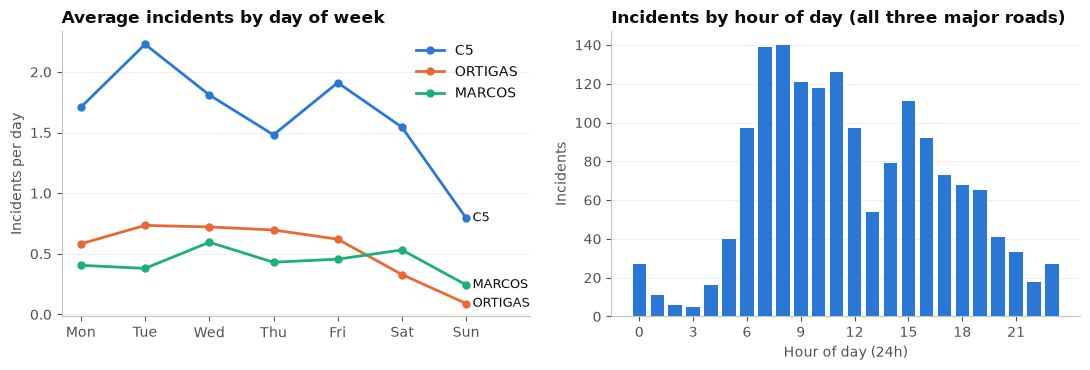

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (c) day-of-week pattern per major road
ax = axes[0]
dow = eng.groupby(['DayOfWeek', 'MajorRoad'])['Incidents'].mean().unstack()
labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for c in major_roads:
    ax.plot(labels, dow[c].values, color=ROAD_COLORS[c], lw=2, marker='o', ms=5, label=c)
    ax.text(6.1, dow[c].values[-1], c, color=INK, va='center', fontsize=9)
ax.set_xlim(-0.3, 7.0)
ax.set_title('Average incidents by day of week'); ax.set_ylabel('Incidents per day')
ax.legend(loc='upper right')

# (d) hour-of-day pattern
ax = axes[1]
hours = inc['Hour'].dropna().astype(int).value_counts().reindex(range(24), fill_value=0)
ax.bar(hours.index, hours.values, color=BLUE, width=0.75)
ax.set_title('Incidents by hour of day (all three major roads)')
ax.set_xlabel('Hour of day (24h)'); ax.set_ylabel('Incidents')
ax.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()

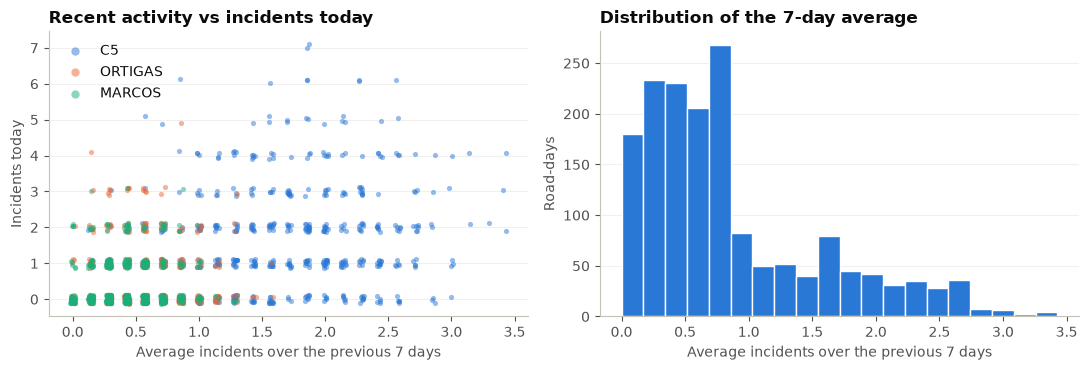

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (e) scatter plot: recent activity vs incidents today
ax = axes[0]
rng_s = np.random.default_rng(RANDOM_STATE)
for r in major_roads:
    d = eng[eng['MajorRoad'] == r]
    ax.scatter(d['Incidents_Roll7'] + rng_s.uniform(-0.02, 0.02, len(d)), d['Incidents'] + rng_s.uniform(-0.12, 0.12, len(d)),
               s=14, color=ROAD_COLORS[r], alpha=0.5, linewidths=0, label=r)
ax.set_xlabel('Average incidents over the previous 7 days'); ax.set_ylabel('Incidents today')
ax.set_title('Recent activity vs incidents today'); ax.legend(loc='upper left', markerscale=1.6)

# (f) distribution of the 7-day average
ax = axes[1]
ax.hist(eng['Incidents_Roll7'], bins=20, color=BLUE, edgecolor='white')
ax.set_title('Distribution of the 7-day average'); ax.set_xlabel('Average incidents over the previous 7 days'); ax.set_ylabel('Road-days')
plt.tight_layout(); plt.show()

### 4.4 Relationship between the features and the target

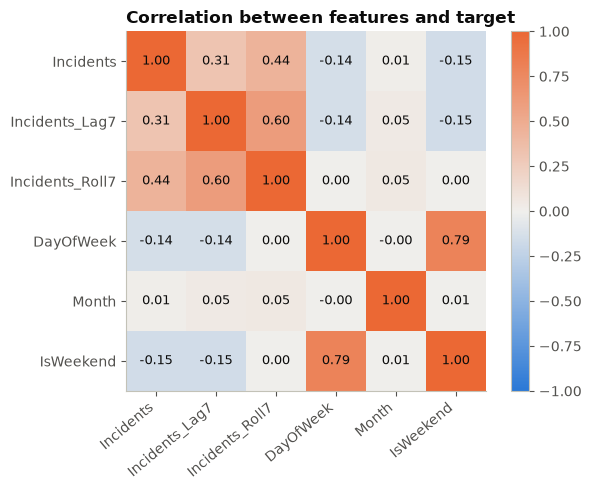

In [23]:
# Correlation heatmap (numeric view of the features and the target)
num = eng[['Incidents', 'Incidents_Lag7', 'Incidents_Roll7', 'DayOfWeek', 'Month', 'IsWeekend']]
corr = num.corr()
cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f0efec', ORANGE])
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', color=INK, fontsize=9)
ax.set_title('Correlation between features and target')
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

### 4.5 Key findings (from the charts above)

1. **The major road matters most.** C5 averages 1.64 incidents per day, against 0.54 for Ortigas and 0.43 for Marcos Highway. Half of all road-days (843 of 1,656) have no reported incident, and only 70 have four or more, so the target is skewed toward small counts. This is why a model is judged against a simple "major road average" baseline.
2. **Weekdays are busier than weekends.** C5 peaks on Tuesdays (about 2.2 per day) and drops to about 0.8 on Sundays; Ortigas falls to almost zero on Sundays. Day of week is weakly negatively correlated with the target (-0.14), and recent activity is positively correlated with it (the 7-day average, 0.44; the same weekday last week, 0.31).
3. **Incidents cluster in the morning.** Reports rise sharply from 6 am and stay high until about noon (roughly 120–140 per hour around 7–11 am), dip around 1 pm and rise again around 3 pm. This suggests deployment is most valuable in the morning rush.
4. **Month shows almost no relationship** with the target (correlation 0.01), so seasonality is weak in this period.
5. **The 7-day average mostly reflects which major road it is.** In the scatter plot, C5 points sit at higher averages (about 1 to 3.4) while Ortigas and Marcos Highway cluster below about 1. Within C5, busy days (4 or more incidents) appear across the whole range, so recent activity is only a weak signal on its own.

## Phase V. Machine Learning Model Development

### 5.1 Data splitting (training and testing sets)

Incidents are a **time series**, so a random split would let the model "see" days after the ones it is tested on. The split is by time instead: **train on everything before 1 Oct 2019, test on 1 Oct 2019 – 29 Feb 2020.**

In [24]:
SPLIT_DATE = pd.Timestamp('2019-10-01')
CAT = ['MajorRoad', 'DayOfWeek', 'Month']
NUM = ['Incidents_Lag7', 'Incidents_Roll7']
TARGET = 'Incidents'

train = eng[eng['Date'] < SPLIT_DATE].reset_index(drop=True)
test = eng[eng['Date'] >= SPLIT_DATE].reset_index(drop=True)
X_train, y_train = train[CAT + NUM], train[TARGET]
X_test, y_test = test[CAT + NUM], test[TARGET]

print(f'Training: {len(train):,} rows ({train.Date.min().date()} -> {train.Date.max().date()})')
print(f'Testing : {len(test):,} rows ({test.Date.min().date()} -> {test.Date.max().date()})')
print(f'Mean incidents/day: train {y_train.mean():.2f}, test {y_test.mean():.2f}')

Training: 1,200 rows (2018-08-27 -> 2019-09-30)
Testing : 456 rows (2019-10-01 -> 2020-02-29)
Mean incidents/day: train 0.88, test 0.86


### 5.2 Model selection and training

**Task:** regression (the target is a count: 0, 1, 2, 3, ...).

| Model | Why it is included |
|---|---|
| **Baseline (mean)** (average of each major road in the training period) | The simplest sensible forecast of the expected count. Any real model must beat it. |
| **Baseline (median)** (median of each major road in the training period) | The best constant guess when the error is measured by MAE, because about half of the road-days are zero. It is the strictest MAE comparison. |
| **Linear Regression** | Simple and easy to interpret; can predict negative counts, which are clipped at 0. |
| **Poisson Regression** | Designed for non-negative counts, so it fits this target naturally. |
| **Random Forest Regressor** | Captures non-linear patterns and interactions without assuming a formula. |

**Assumptions:** past patterns (major road and weekday effects, recent counts) continue; incidents are reported consistently; the period from March 2020 is excluded. **Forecast horizon:** the model predicts **one day ahead**, because `Incidents_Lag7` and `Incidents_Roll7` use the actual counts up to the day before.

**Model configuration:**
- Inputs: major road, day of week and month (one-hot encoded), plus `Incidents_Lag7` and `Incidents_Roll7` (standardized); target `Incidents`.
- Linear Regression: default settings, predictions clipped at 0.
- Poisson Regression: `alpha = 0.001`, `max_iter = 1000`.
- Random Forest: 300 trees, `min_samples_leaf = 5`, `random_state = 42`.
- Split date 1 Oct 2019; 4-fold expanding-window time-series cross-validation on the training period (folds cut by date, so the three roads of one day are never split); random seed 42.

**Validation strategy:** expanding-window time-series cross-validation (4 folds) on the training period selects the model, using the lowest cross-validated **RMSE** because planners need the expected count (MAE alone favours predicting the median). The test period is used once at the end, and the encoder and scaler are re-fitted inside every fold.

In [25]:
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM),
])

models = {
    'Linear Regression': LinearRegression(),
    'Poisson Regression': PoissonRegressor(alpha=1e-3, max_iter=1000),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE),
}
pipes = {name: Pipeline([('prep', preprocess), ('model', m)]) for name, m in models.items()}

def predict(name, pipe, X):
    p = pipe.predict(X)
    return np.clip(p, 0, None)          # a count cannot be negative

def baseline_fit_predict(train_df, X, how='mean'):
    """Per-major-road baseline: the road's mean (default) or median count in the training data."""
    stat = train_df.groupby('MajorRoad')[TARGET].agg(how)
    return X['MajorRoad'].map(stat).values

def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5

# Time-series cross-validation on the training period. The folds are cut by DATE (not by row),
# so the three major roads of one day are never split between training and validation.
BASELINES = {'Baseline (mean)': 'mean', 'Baseline (median)': 'median'}
names_cv = list(BASELINES) + list(pipes)
cv_mae = {n: [] for n in names_cv}
cv_rmse = {n: [] for n in names_cv}
dates = np.sort(train['Date'].unique())
for tr_d, va_d in TimeSeriesSplit(n_splits=4).split(dates):
    tr_df = train[train['Date'].isin(dates[tr_d])]
    va_df = train[train['Date'].isin(dates[va_d])]
    for n, how in BASELINES.items():
        p = baseline_fit_predict(tr_df, va_df[CAT + NUM], how)
        cv_mae[n].append(mean_absolute_error(va_df[TARGET], p)); cv_rmse[n].append(rmse(va_df[TARGET], p))
    for n, pipe in pipes.items():
        fold_pipe = clone(pipe).fit(tr_df[CAT + NUM], tr_df[TARGET])       # fresh copy for every fold
        p = predict(n, fold_pipe, va_df[CAT + NUM])
        cv_mae[n].append(mean_absolute_error(va_df[TARGET], p)); cv_rmse[n].append(rmse(va_df[TARGET], p))

cv_table = pd.DataFrame({'CV MAE (mean of 4 folds)': {n: np.mean(v) for n, v in cv_mae.items()},
                         'CV RMSE (mean of 4 folds)': {n: np.mean(v) for n, v in cv_rmse.items()}}).round(3)
display(cv_table)

# The model is selected on RMSE: planners need the expected count, and RMSE rewards a good estimate of the mean.
# (MAE alone favors predicting the median, which is 0 or 1 for most roads.)
candidates = cv_table.drop(index=list(BASELINES))
best_name = candidates['CV RMSE (mean of 4 folds)'].idxmin()
print('Best model by cross-validation (lowest RMSE):', best_name)

,CV MAE (mean of 4 folds),CV RMSE (mean of 4 folds)
Baseline (mean),0.817,1.043
Baseline (median),0.710,1.143
Linear Regression,0.765,1.016
Poisson Regression,0.779,1.019
Random Forest,0.788,1.034


Best model by cross-validation (lowest RMSE): Linear Regression


In [26]:
# Final training on the whole training period
for pipe in pipes.values():
    pipe.fit(X_train, y_train)
print('Trained:', ', '.join(pipes))

Trained: Linear Regression, Poisson Regression, Random Forest


### 5.3 Prediction values

In [27]:
test_pred = {n: baseline_fit_predict(train, X_test, how) for n, how in BASELINES.items()}
for n, pipe in pipes.items():
    test_pred[n] = predict(n, pipe, X_test)

sample = test[['Date', 'MajorRoad', TARGET]].copy()
sample[f'Predicted ({best_name})'] = test_pred[best_name].round(2)
print('First 10 predictions on the test period:')
sample.head(10)

First 10 predictions on the test period:


,Date,MajorRoad,Incidents,Predicted (Linear Regression)
0,2019-10-01,C5,1,1.99
1,2019-10-01,MARCOS,1,0.82
2,2019-10-01,ORTIGAS,2,0.93
3,2019-10-02,C5,1,2.01
4,2019-10-02,MARCOS,1,0.84
5,2019-10-02,ORTIGAS,0,0.99
6,2019-10-03,C5,2,1.77
7,2019-10-03,MARCOS,0,0.64
8,2019-10-03,ORTIGAS,2,0.75
9,2019-10-04,C5,5,1.84


## Phase VI. Model Evaluation and Interpretation

### 6.1 Visualization of model analysis

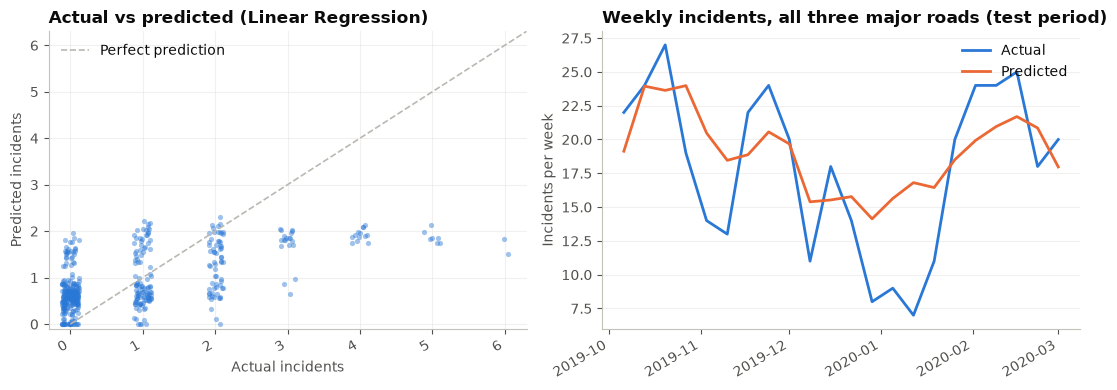

In [28]:
best_pred = test_pred[best_name]
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) actual vs predicted (jitter on the actual value because counts are whole numbers)
ax = axes[0]
ax.scatter(y_test + rng.uniform(-0.12, 0.12, len(y_test)), best_pred, s=14, color=BLUE, alpha=0.45, linewidths=0)
lim = max(y_test.max(), best_pred.max()) + 0.3
ax.plot([0, lim], [0, lim], color=GREY, ls='--', lw=1.2, label='Perfect prediction')
ax.set_xlim(-0.3, lim); ax.set_ylim(-0.1, lim)
ax.grid(axis='x')
ax.set_xlabel('Actual incidents'); ax.set_ylabel('Predicted incidents')
ax.set_title(f'Actual vs predicted ({best_name})'); ax.legend(loc='upper left')

# (b) weekly totals over the test period
ax = axes[1]
wk = pd.DataFrame({'Date': test['Date'], 'Actual': y_test.values, 'Predicted': best_pred}).set_index('Date').resample('W').sum()
ax.plot(wk.index, wk['Actual'], color=BLUE, lw=2, label='Actual')
ax.plot(wk.index, wk['Predicted'], color=ORANGE, lw=2, label='Predicted')
ax.set_title('Weekly incidents, all three major roads (test period)')
ax.set_ylabel('Incidents per week'); ax.legend(loc='upper right')
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

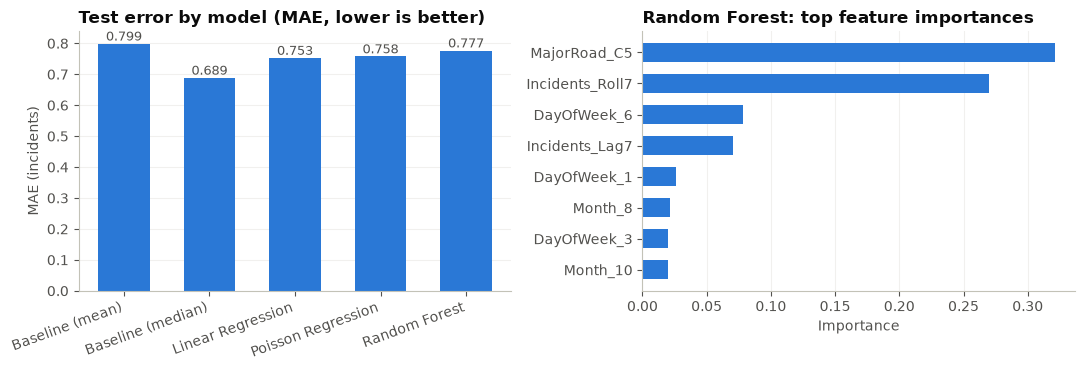

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# (c) test MAE by model
ax = axes[0]
mae = {n: mean_absolute_error(y_test, p) for n, p in test_pred.items()}
names = list(mae)
ax.bar(names, [mae[n] for n in names], color=BLUE, width=0.6)
for i, n in enumerate(names):
    ax.text(i, mae[n] + 0.01, f'{mae[n]:.3f}', ha='center', color=MUTED, fontsize=9)
ax.set_title('Test error by model (MAE, lower is better)'); ax.set_ylabel('MAE (incidents)')
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20, ha='right')

# (d) which features does the Random Forest rely on?
ax = axes[1]
rf = pipes['Random Forest']
fn = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=fn).sort_values().tail(8)
imp.index = [i.replace('cat__', '').replace('num__', '') for i in imp.index]
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('Random Forest: top feature importances'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.show()

### Feature importance

The Random Forest importances sum to 1; the Linear Regression coefficients are on standardized lag features and one-hot encoded categories, and are not significance-tested.

In [30]:
fn = [i.replace('cat__', '').replace('num__', '') for i in pipes['Random Forest'].named_steps['prep'].get_feature_names_out()]
lr = pipes['Linear Regression'].named_steps['model']
rf = pipes['Random Forest'].named_steps['model']
imp_table = pd.DataFrame({'Linear Regression coefficient': lr.coef_, 'Random Forest importance': rf.feature_importances_}, index=fn)
imp_table.sort_values('Random Forest importance', ascending=False).head(10).round(3)

,Linear Regression coefficient,Random Forest importance
MajorRoad_C5,0.545,0.321
Incidents_Roll7,0.165,0.270
DayOfWeek_6,-0.529,0.078
Incidents_Lag7,0.001,0.070
DayOfWeek_1,0.217,0.026
Month_8,0.063,0.021
DayOfWeek_3,0.002,0.020
Month_10,0.188,0.020
Month_7,-0.036,0.018
DayOfWeek_5,-0.020,0.017


### 6.2 Performance Metrics

MAE (average miss in incidents), RMSE (penalizes big misses more) and R² (share of the variation explained) on the **test period**, compared with the baseline.

In [31]:
rows = []
for n, p in test_pred.items():
    rows.append({'Model': n,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': rmse(y_test, p),
                 'R2': r2_score(y_test, p)})
metrics = pd.DataFrame(rows).set_index('Model').round(3)
metrics['CV MAE (train)'] = cv_table['CV MAE (mean of 4 folds)']
metrics['CV RMSE (train)'] = cv_table['CV RMSE (mean of 4 folds)']
display(metrics)

print(f'Best model by cross-validation (lowest RMSE): {best_name}')
print()
print('Test MAE by major road for', best_name)
by_c = pd.DataFrame({'MajorRoad': test['MajorRoad'], 'abs_err': np.abs(y_test.values - best_pred)}).groupby('MajorRoad')['abs_err'].mean().round(3)
print(by_c.to_string())

,MAE,RMSE,R2,CV MAE (train),CV RMSE (train)
Model,,,,,
Baseline (mean),0.799,1.019,0.273,0.817,1.043
Baseline (median),0.689,1.155,0.067,0.710,1.143
Linear Regression,0.753,0.976,0.333,0.765,1.016
Poisson Regression,0.758,0.962,0.353,0.779,1.019
Random Forest,0.777,1.001,0.299,0.788,1.034


Best model by cross-validation (lowest RMSE): Linear Regression

Test MAE by major road for Linear Regression
MajorRoad
C5         1.137
MARCOS     0.533
ORTIGAS    0.588


### 6.3 Interpretation of the Results

**Interpretation of the metrics.** On the test period (Oct 2019 – Feb 2020), all three models beat the per-road **mean** baseline (MAE 0.799, RMSE 1.019, R² 0.273) on every measure:

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Baseline (mean) | 0.799 | 1.019 | 0.273 |
| Baseline (median) | 0.689 | 1.155 | 0.067 |
| Linear Regression | 0.753 | 0.976 | 0.333 |
| Poisson Regression | 0.758 | 0.962 | 0.353 |
| Random Forest | 0.777 | 1.001 | 0.299 |

The ranking depends on the metric. About half of the road-days are zero, and MAE is minimized by predicting the **median** (0 or 1 for most roads), so the per-road median baseline reaches the lowest MAE (0.689) but has the worst RMSE (1.155) and R² (0.07) because it never expects any busy day. The models instead estimate the expected count, which is what planners need, and they are better on RMSE and R². Cross-validation on the training period chose Linear Regression (CV RMSE 1.016, against 1.043 for the mean baseline); Poisson Regression had the best RMSE and R² on the test period. The differences between the three models are small. On average the best model misses by about 0.75 incidents per road-day, about 6% lower MAE than the mean baseline.

**What the model achieved.** It captures the general level of activity: it knows C5 is far busier than the other major roads, that weekends are quieter and that busy weeks tend to follow busy weeks (the weekly chart follows the actual trend). It explains about one third of the variation in daily counts (R² about 0.33).

**What it failed to do.** It never predicts more than about 2 incidents in a day, so it misses the busiest days (4–7 incidents). It also misses sudden drops, such as the very quiet weeks around the Christmas–New Year holidays, where actual counts fell to 7–9 per week and the model predicted 14–16. Most of the accuracy comes from the major road and the recent average, not from the calendar. The error is largest on C5 (MAE 1.14, against 0.53 for Marcos Highway and 0.59 for Ortigas) because C5 has the highest and most variable counts.

**Is the model useful for the intended application?** Partly. It tells planners which major road is busiest and that weekdays are busier than weekends, but that is largely what the per-road average already says, and it does not beat a simple per-road median on MAE. It is a rough guide for where to focus resources, not a precise forecast of a given day.

### 6.4 Demonstration: predicting a road and a date

This cell uses the selected model (Linear Regression) on the test period. Change `DEMO_ROAD` and `DEMO_DATE` to any major road and any date from 1 Oct 2019 to 29 Feb 2020. It shows the model's prediction next to the baseline and the actual MMDA-reported count for that day, then the same road for the following 7 days.

In [32]:
# Choose a major road and a date in the test period
DEMO_ROAD = 'C5'            # 'C5', 'ORTIGAS' or 'MARCOS'
DEMO_DATE = '2019-10-15'    # between 2019-10-01 and 2020-02-29

day = pd.Timestamp(DEMO_DATE)
week = test[(test['MajorRoad'] == DEMO_ROAD) & (test['Date'] >= day) & (test['Date'] < day + pd.Timedelta(days=7))].copy()
assert len(week) > 0, 'Pick a road and a date inside the test period (1 Oct 2019 - 29 Feb 2020).'

week['Day'] = week['Date'].dt.day_name()
week['Baseline'] = baseline_fit_predict(train, week[CAT + NUM], 'mean').round(2)
week[f'Predicted ({best_name})'] = predict(best_name, pipes[best_name], week[CAT + NUM]).round(2)
week = week.rename(columns={'Incidents': 'Actual'})

first = week.iloc[0]
print(f"{DEMO_ROAD} on {first['Date'].date()} ({first['Day']}):")
print(f"  Model prediction : {first[f'Predicted ({best_name})']:.2f} incidents")
print(f"  Baseline (road mean): {first['Baseline']:.2f} incidents")
print(f"  Actual (MMDA-reported) : {int(first['Actual'])} incidents")
print()
print(f'Same road, next {len(week)} days:')
week[['Date', 'Day', 'Actual', 'Baseline', f'Predicted ({best_name})']].reset_index(drop=True)

C5 on 2019-10-15 (Tuesday):
  Model prediction : 2.09 incidents
  Baseline (road mean): 1.60 incidents
  Actual (MMDA-reported) : 4 incidents

Same road, next 7 days:


,Date,Day,Actual,Baseline,Predicted (Linear Regression)
0,2019-10-15,Tuesday,4,1.6,2.09
1,2019-10-16,Wednesday,2,1.6,2.15
2,2019-10-17,Thursday,2,1.6,1.99
3,2019-10-18,Friday,5,1.6,1.98
4,2019-10-19,Saturday,3,1.6,1.96
5,2019-10-20,Sunday,2,1.6,1.52
6,2019-10-21,Monday,2,1.6,2.10


## Phase VII. Recommendations and Responsible Data Use

### 7.1 How the results could help the stakeholders

C5 should be the first priority when MMDA and the Pasig City traffic management office place enforcers and tow trucks, because it averages 1.64 incidents per day, about three times Ortigas (0.54) and Marcos Highway (0.43). Reported incidents are lower on Sundays and highest around Tuesday on C5, so weekly schedules can put more units on weekdays, and morning coverage (about 6 to 11 am) is where extra units matter most. The model's predicted count per major road can serve as a quick baseline expectation of how busy a day is likely to be, to be adjusted by staff who know about events and road works.

### 7.2 Additional data and validation required

The model predicts one day ahead, because its features use the previous days' actual counts. To plan a week ahead, as the traffic office would for scheduling, the features would have to be rebuilt with a longer lead (for example, using only information that is at least 7 days old), and the model re-tested. More data is also needed: incident records beyond what MMDA tweets, the 187 rows without a city, and a longer period that includes 2021 onward so the model can be tested after the pandemic period. More features would also help, such as holidays and school calendars (the model missed the quiet holiday weeks), rainfall and weather, traffic volume, and scheduled road works or events. For validation, the predictions should be compared with MMDA's and the city's own incident records and tested on later periods, the stakeholders should be asked what level of error is acceptable, and the model should be tried in a small pilot before anyone relies on it.

### 7.3 Limitations of the dataset and model

**Dataset**

- The data holds only incidents that MMDA chose to tweet; the dataset's author notes it does not represent all incidents, and because MMDA's jurisdiction is mainly national roads the data is biased toward roads such as EDSA and C5. Major roads and times that MMDA monitors more closely look busier.
- The tweets were parsed automatically by a script, so some fields (for example times and locations) contain parsing errors.
- Many rows have no `City`, including Marcos Highway rows, so the Marcos Highway counts are probably too low.
- Only about 18 months before March 2020 are used. The author reports a collection gap in early 2020 and traffic also fell during the lockdown, so later months are excluded.
- Coordinates are location-level (about 100 distinct points), and 74 incidents outside the three major roads were left out.
- Days with no record are treated as days with no incident, which may not always be true.

**Model**

- It explains only about one third of the variation (R² about 0.33), so it is a planning aid, not a precise forecast.
- It never predicts more than about 2 incidents in a day, so it misses the busiest days.
- It is a one-day-ahead model, and it does not beat a per-road median baseline on MAE (0.753 against 0.689), only on RMSE and R².
- It gives no estimate of its own uncertainty, and because it was trained on one period it may not hold when traffic patterns change.

### 7.4 Data privacy, consent, fairness and responsible AI

The data is public information posted by a government agency and contains no names, plate numbers or other personal details, only vehicle types and places. No individual consent was needed, and the source is cited. Its CC BY-NC-SA 4.0 license permits non-commercial use with attribution, which fits this coursework, and any shared derived dataset should carry the same license. On fairness, a road with few reported incidents is not necessarily safer, because reporting depends on where and when MMDA posts, and the results should not be used to blame drivers, neighborhoods or particular vehicle types. Any real use should keep a person responsible for deciding where to deploy resources; the model informs the decision and does not make it.

### 7.5 Is the model ready for practical use?

Not yet. The improvement over a simple per-road average is modest (MAE 0.753 against 0.799, RMSE 0.976 against 1.019) and it does not beat a per-road median on MAE (0.689), the model misses busy days and holiday dips, and it was tested on only five months. It needs the additional data and validation in VII.2, and a pilot with the traffic office, before it should support real deployment decisions.

## References

**Data**

Brotoisworo, P. (n.d.). *Manila Traffic Incident Data: Incidents Reported by the Metro Manila Development Authority Twitter Page* [Data set]. Kaggle. https://www.kaggle.com/datasets/esparko/mmda-traffic-incident-data. Licensed under CC BY-NC-SA 4.0. The original alerts are from the Metro Manila Development Authority (@MMDA) on Twitter/X

Sigales, J. (2025, June 27). Most Metro Manila road crashes in 2024 took place on Edsa, C5 — MMDA. *INQUIRER.net*. https://newsinfo.inquirer.net/2075306/most-metro-manila-road-crashes-in-2024-took-place-on-edsa-c5-mmda

Wheels.ph. (2019, June 2). MMDA: PH lost P3.5-B per day to traffic in 2018. *Philstar Wheels*. https://wheels.ph/first-look/2019/06/02/6310/mmda-ph-lost-p3-5-b-per-day-to-traffic-in-2018/

Chua, P. (2020, February 26). For the third year running, C5 is Metro Manila's deadliest road. *Top Gear Philippines*. https://www.topgear.com.ph/news/motoring-news/deadliest-road-c5-metro-manila-sa3557-20200226-src-esquireph (originally published in Esquire Philippines; figures from the MMDA's 2019 MMARAS report).

Top Gear Philippines. (2020, February 24). MMDA reports an all-time high of 121,771 road accidents in 2019. https://www.topgear.com.ph/news/motoring-news/mmda-mmaras-2019-report-a4354-20200224

**Tools and Libraries:** Python, pandas, NumPy, scikit-learn and Matplotlib (the versions used are printed in Phase II).